In [2]:
from HPC.Upload.pyfiles.classes import *
import matplotlib.pyplot as plt


plt.rcParams.update({
    "text.usetex": True,
    "font.family": "Bitstream Vera Sans",
    "font.sans-serif": "Helvetica",
})

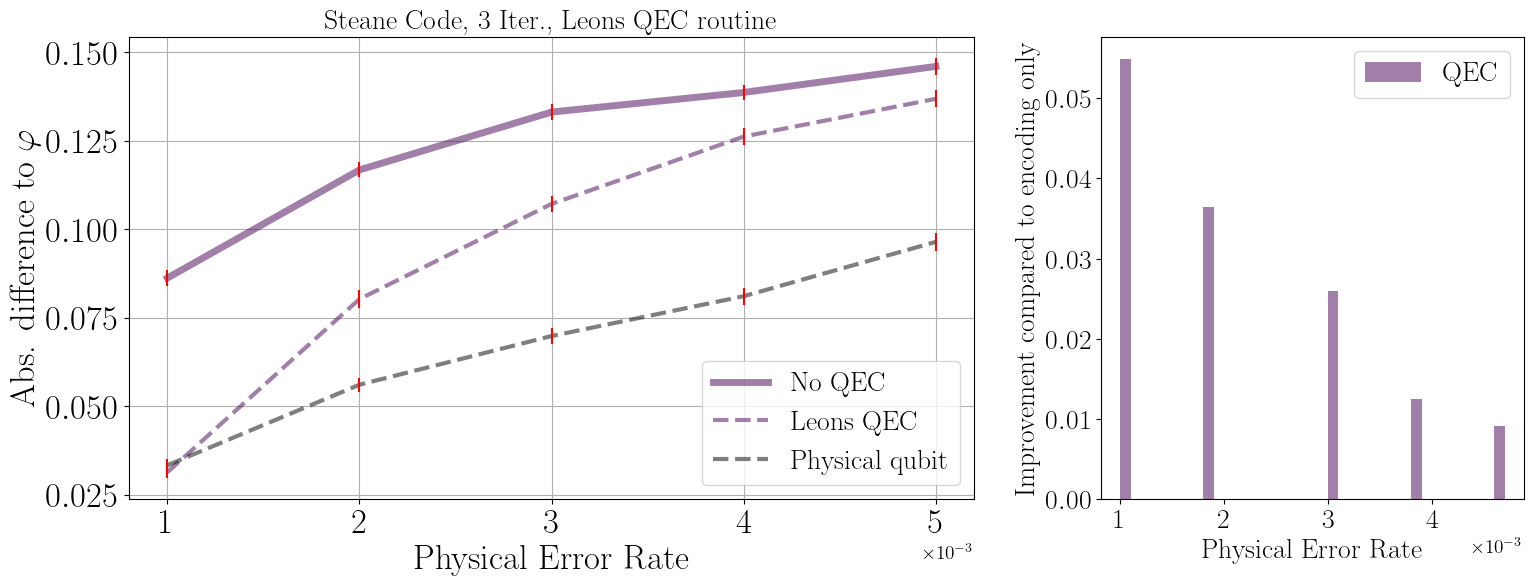

In [3]:
# Steane Code mit Leons QEC Protokoll
shots = 400

p1, y1, y_qec1, err1, err_qec1 = np.loadtxt("HPC/text/steane_leonprotocol_further.txt", delimiter = ",")
# p2, y2, err2 = np.loadtxt("HPC/text/d5_htoffcxbeam_infbias_noqec_0.txt", delimiter = ",")
# p3, y3, y_qec3, err3, err_qec3 = np.loadtxt("HPC/text/d3_htoffcxbeam_infbias_idealqec.txt", delimiter = ",")
# p4, y_qec4, err_qec4 = np.loadtxt("HPC/text/d5_htoffcxbeam_infbias_qec_0.txt", delimiter = ",")                 #100 Shots!
# p5, y5, y_qec5, err5, err_qec5 = np.loadtxt("HPC/text/bigsteane_idealqec_lots.txt", delimiter = ",")

p6, y6, err6 = np.loadtxt("HPC/text/physicalq_steane_further.txt", delimiter = ",")

fig, (ax1,ax2) = plt.subplots(1,2,figsize=(18,6), gridspec_kw={"width_ratios": [2, 1]})

# try:
colors = plt.cm.viridis(np.linspace(0, 1, 7))
# except TypeError:
#     pass

ax1.plot(p1,y1, label="No QEC", marker = "", linestyle = "-", markersize = 20, alpha = 0.5, color = colors[0], linewidth=5)
ax1.errorbar(p1, y1, yerr=err1, ecolor="red", linestyle="")

ax1.plot(p1, y_qec1, label="Leons QEC", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = colors[0], linewidth=3)
ax1.errorbar(p1, y_qec1, yerr=err_qec1, ecolor="red", linestyle="")

# ax1.plot(p2, y2, label="d=5", marker = "", linestyle = "-", markersize = 20, alpha = 0.5, color = colors[2], linewidth=5)
# ax1.errorbar(p2, y2, yerr=err2, ecolor="red", linestyle="")

# ax1.plot(p3, y_qec3, label="d=3, ideal qec", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = colors[5], linewidth=3)
# ax1.errorbar(p3, y_qec3, yerr=err_qec3, ecolor="red", linestyle="")

# ax1.plot(p4, y_qec4, label="d=5, QEC", marker = ".", linestyle = "--", markersize = 20, alpha = 0.5, color = colors[6], linewidth=3)
# ax1.errorbar(p4, y_qec4, yerr=err_qec4, ecolor="red", linestyle="")

# ax1.plot(p5, y_qec5, label="d=5, ideal QEC", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = colors[4], linewidth=3)
# ax1.errorbar(p5, y_qec5, yerr=err_qec5, ecolor="red", linestyle="")

ax1.plot(p6, y6, label="Physical qubit", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = "black", linewidth=3)
ax1.errorbar(p6, y6, yerr=err6, ecolor="red", linestyle="")


ax1.set_title(r"Steane Code, 3 Iter., Leons QEC routine", fontsize=20)
ax1.set_xlabel("Physical Error Rate", fontsize=25)
ax1.set_ylabel(r"Abs. difference to $\varphi$", fontsize=25)
ax1.tick_params(axis='both', which='major', labelsize=25)
ax1.grid()
ax1.legend(fontsize=20)
############################################################################################################################
x_hist = np.asarray(p1)

qec_hist = -(np.asarray(y_qec1) - np.asarray(y1))
# idealqec_hist = -(np.asarray(y_qec3) - np.asarray(y1))
# ftqec_hist = -(np.asarray(y_qec4) - np.asarray(y1))
# ftqec_lots_hist = -(np.asarray(y_qec3) - np.asarray(y1))
# d5_hist = -(np.asarray(y2) - np.asarray(y1))

# Use the same bin edges for all histograms
bins = np.histogram_bin_edges(x_hist, bins=10)
bin_width = bins[1] - bins[0]

# Calculate weighted histogram values
qec_counts, _ = np.histogram(x_hist, bins=bins, weights=qec_hist)
# idealqec_counts, _ = np.histogram(x_hist, bins=bins, weights=idealqec_hist)
# ftqec_counts, _ = np.histogram(x_hist, bins=bins, weights=ftqec_hist)
# ftqec_lots_counts, _ = np.histogram(x_hist, bins=bins, weights=ftqec_lots_hist)
# d5_counts, _ = np.histogram(x_hist, bins=bins, weights=d5_hist)

# Four bars side-by-side within each bin
bar_width = bin_width / 4
x = bins[:-1]

ax2.bar(
    x,
    qec_counts,
    width=bar_width,
    align="edge",
    alpha=0.5,
    color=colors[0],
    label="QEC"
)

# ax2.bar(
#     x + bar_width,
#     idealqec_counts,
#     width=bar_width,
#     align="edge",
#     alpha=0.5,
#     color=colors[5],
#     label="ideal QEC"
# )

# ax2.bar(
#     x + 2 * bar_width,
#     ftqec_counts,
#     width=bar_width,
#     align="edge",
#     alpha=0.5,
#     color=colors[4],
#     label="2-FTEC"
# )

# ax2.bar(
#     x + 3 * bar_width,
#     ftqec_lots_counts,
#     width=bar_width,
#     align="edge",
#     alpha=0.5,
#     color=colors[5],
#     label="2-FTEC (lots)"
# )

# ax2.bar(
#     x +  bar_width,
#     d3_idealqec_counts,
#     width=bar_width,
#     align="edge",
#     alpha=0.5,
#     color=colors[4],
#     label="ideal QEC"
# )


ax2.legend(fontsize=20)
ax2.tick_params(axis='both', which='major', labelsize=20)
ax2.set_xlabel("Physical Error Rate", fontsize=20)
ax2.set_ylabel(r"Improvement compared to encoding only", fontsize=20)
ax1.ticklabel_format(axis="x", style="sci", scilimits=(0, 0)), ax1.xaxis.get_offset_text().set_fontsize(14), ax2.xaxis.get_offset_text().set_fontsize(14)
ax2.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))

############################################################################################################################
#plt.tight_layout()
# plt.savefig("14.png", bbox_inches="tight" ,dpi=200)
plt.show()

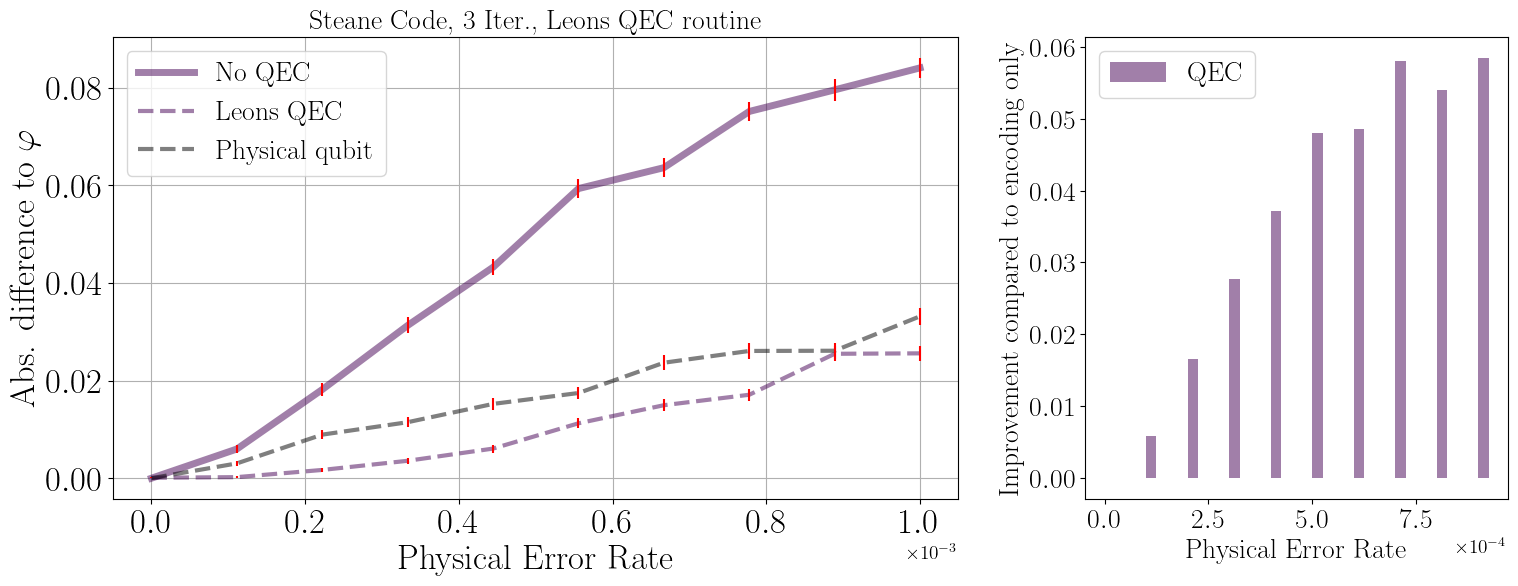

In [4]:
# Steane Code mit Leons QEC Protokoll
shots = 400

p1, y1, y_qec1, err1, err_qec1 = np.loadtxt("HPC/text/steane_leonprotocol.txt", delimiter = ",")
# p2, y2, err2 = np.loadtxt("HPC/text/d5_htoffcxbeam_infbias_noqec_0.txt", delimiter = ",")
# p3, y3, y_qec3, err3, err_qec3 = np.loadtxt("HPC/text/d3_htoffcxbeam_infbias_idealqec.txt", delimiter = ",")
# p4, y_qec4, err_qec4 = np.loadtxt("HPC/text/d5_htoffcxbeam_infbias_qec_0.txt", delimiter = ",")                 #100 Shots!
# p5, y5, y_qec5, err5, err_qec5 = np.loadtxt("HPC/text/bigsteane_idealqec_lots.txt", delimiter = ",")

p6, y6, err6 = np.loadtxt("HPC/text/physicalq_steane.txt", delimiter = ",")

fig, (ax1,ax2) = plt.subplots(1,2,figsize=(18,6), gridspec_kw={"width_ratios": [2, 1]})

# try:
colors = plt.cm.viridis(np.linspace(0, 1, 7))
# except TypeError:
#     pass

ax1.plot(p1,y1, label="No QEC", marker = "", linestyle = "-", markersize = 20, alpha = 0.5, color = colors[0], linewidth=5)
ax1.errorbar(p1, y1, yerr=err1, ecolor="red", linestyle="")

ax1.plot(p1, y_qec1, label="Leons QEC", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = colors[0], linewidth=3)
ax1.errorbar(p1, y_qec1, yerr=err_qec1, ecolor="red", linestyle="")

# ax1.plot(p2, y2, label="d=5", marker = "", linestyle = "-", markersize = 20, alpha = 0.5, color = colors[2], linewidth=5)
# ax1.errorbar(p2, y2, yerr=err2, ecolor="red", linestyle="")

# ax1.plot(p3, y_qec3, label="d=3, ideal qec", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = colors[5], linewidth=3)
# ax1.errorbar(p3, y_qec3, yerr=err_qec3, ecolor="red", linestyle="")

# ax1.plot(p4, y_qec4, label="d=5, QEC", marker = ".", linestyle = "--", markersize = 20, alpha = 0.5, color = colors[6], linewidth=3)
# ax1.errorbar(p4, y_qec4, yerr=err_qec4, ecolor="red", linestyle="")

# ax1.plot(p5, y_qec5, label="d=5, ideal QEC", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = colors[4], linewidth=3)
# ax1.errorbar(p5, y_qec5, yerr=err_qec5, ecolor="red", linestyle="")

ax1.plot(p6, y6, label="Physical qubit", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = "black", linewidth=3)
ax1.errorbar(p6, y6, yerr=err6, ecolor="red", linestyle="")


ax1.set_title(r"Steane Code, 3 Iter., Leons QEC routine", fontsize=20)
ax1.set_xlabel("Physical Error Rate", fontsize=25)
ax1.set_ylabel(r"Abs. difference to $\varphi$", fontsize=25)
ax1.tick_params(axis='both', which='major', labelsize=25)
ax1.grid()
ax1.legend(fontsize=20)
############################################################################################################################
x_hist = np.asarray(p1)

qec_hist = -(np.asarray(y_qec1) - np.asarray(y1))
# idealqec_hist = -(np.asarray(y_qec3) - np.asarray(y1))
# ftqec_hist = -(np.asarray(y_qec4) - np.asarray(y1))
# ftqec_lots_hist = -(np.asarray(y_qec3) - np.asarray(y1))
# d5_hist = -(np.asarray(y2) - np.asarray(y1))

# Use the same bin edges for all histograms
bins = np.histogram_bin_edges(x_hist, bins=10)
bin_width = bins[1] - bins[0]

# Calculate weighted histogram values
qec_counts, _ = np.histogram(x_hist, bins=bins, weights=qec_hist)
# idealqec_counts, _ = np.histogram(x_hist, bins=bins, weights=idealqec_hist)
# ftqec_counts, _ = np.histogram(x_hist, bins=bins, weights=ftqec_hist)
# ftqec_lots_counts, _ = np.histogram(x_hist, bins=bins, weights=ftqec_lots_hist)
# d5_counts, _ = np.histogram(x_hist, bins=bins, weights=d5_hist)

# Four bars side-by-side within each bin
bar_width = bin_width / 4
x = bins[:-1]

ax2.bar(
    x,
    qec_counts,
    width=bar_width,
    align="edge",
    alpha=0.5,
    color=colors[0],
    label="QEC"
)

# ax2.bar(
#     x + bar_width,
#     idealqec_counts,
#     width=bar_width,
#     align="edge",
#     alpha=0.5,
#     color=colors[5],
#     label="ideal QEC"
# )

# ax2.bar(
#     x + 2 * bar_width,
#     ftqec_counts,
#     width=bar_width,
#     align="edge",
#     alpha=0.5,
#     color=colors[4],
#     label="2-FTEC"
# )

# ax2.bar(
#     x + 3 * bar_width,
#     ftqec_lots_counts,
#     width=bar_width,
#     align="edge",
#     alpha=0.5,
#     color=colors[5],
#     label="2-FTEC (lots)"
# )

# ax2.bar(
#     x +  bar_width,
#     d3_idealqec_counts,
#     width=bar_width,
#     align="edge",
#     alpha=0.5,
#     color=colors[4],
#     label="ideal QEC"
# )


ax2.legend(fontsize=20)
ax2.tick_params(axis='both', which='major', labelsize=20)
ax2.set_xlabel("Physical Error Rate", fontsize=20)
ax2.set_ylabel(r"Improvement compared to encoding only", fontsize=20)
ax1.ticklabel_format(axis="x", style="sci", scilimits=(0, 0)), ax1.xaxis.get_offset_text().set_fontsize(14), ax2.xaxis.get_offset_text().set_fontsize(14)
ax2.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))

############################################################################################################################
#plt.tight_layout()
# plt.savefig("14.png", bbox_inches="tight" ,dpi=200)
plt.show()

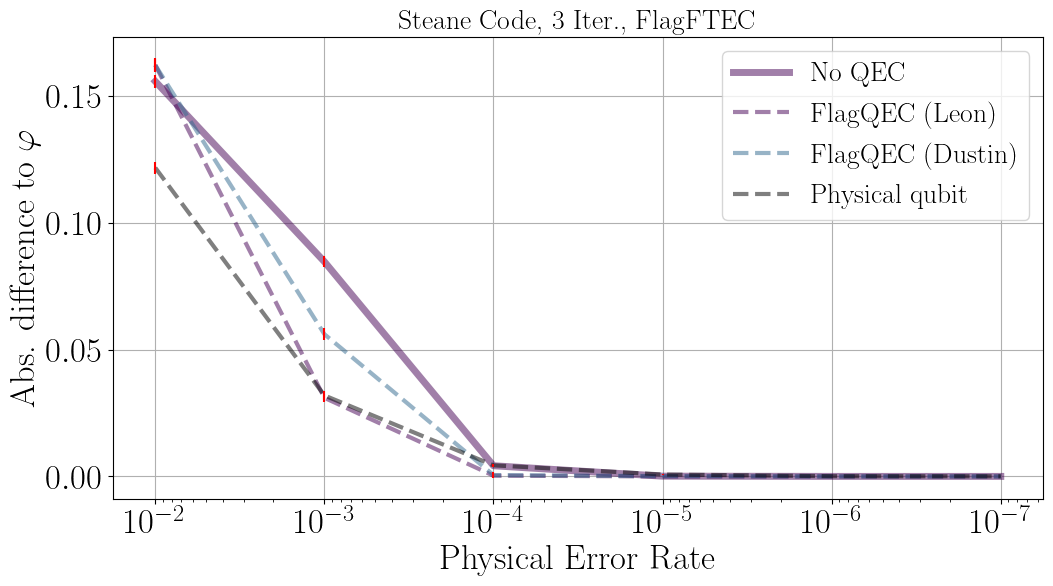

In [5]:
# Phaseflipcode mit bias preserving [H,X,Z,CX,CCX] Gateset, improved mit beamsearch, aka etwa 20% weniger CX, RZ und nur einer Unitary U, nicht 2xsqrt(U)!!!
shots = 400

p1, y1, y_qec1, err1, err_qec1 = np.loadtxt("HPC/text/steane_leonprotocol_crossover.txt", delimiter = ",")
p2, y2, y_qec2, err2, err_qec2 = np.loadtxt("HPC/text/steane_protocol_crossover.txt", delimiter = ",")
# p3, y_qec3, err_qec3 = np.loadtxt("HPC/text/d3_rz_short_crossover_shorqec.txt", delimiter = ",")
# p4, y_qec4, err_qec4 = np.loadtxt("HPC/text/d5_rz_short_qec_0.txt", delimiter = ",")                
# p5, y5, y_qec5, err5, err_qec5 = np.loadtxt("HPC/text/bigsteane_idealqec_lots.txt", delimiter = ",")
p6, y6, err6 = np.loadtxt("HPC/text/physicalq_steane_crossover.txt", delimiter =",")

fig, ax1 = plt.subplots(figsize=(12,6))

# try:
colors = plt.cm.viridis(np.linspace(0, 1, 7))
# except TypeError:
#     pass

ax1.plot(p1,y1, label="No QEC", marker = "", linestyle = "-", markersize = 20, alpha = 0.5, color = colors[0], linewidth=5)
ax1.errorbar(p1, y1, yerr=err1, ecolor="red", linestyle="")

ax1.plot(p1, y_qec1, label="FlagQEC (Leon)", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = colors[0], linewidth=3)
ax1.errorbar(p1, y_qec1, yerr=err_qec1, ecolor="red", linestyle="")

ax1.plot(p2, y_qec2, label="FlagQEC (Dustin)", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = colors[2], linewidth=3)
ax1.errorbar(p2, y_qec2, yerr=err2, ecolor="red", linestyle="")

# ax1.plot(p3, y_qec3, label="d=3, Shor QEC", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = colors[5], linewidth=3)
# ax1.errorbar(p3, y_qec3, yerr=err_qec3, ecolor="red", linestyle="")

# ax1.plot(p4, y_qec4, label="d=5, QEC", marker = ".", linestyle = "--", markersize = 20, alpha = 0.5, color = colors[6])
# ax1.errorbar(p4, y_qec4, yerr=err_qec4, ecolor="red", linestyle="")

# ax1.plot(p5, y_qec5, label="d=5, ideal QEC", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = colors[4], linewidth=3)
# ax1.errorbar(p5, y_qec5, yerr=err_qec5, ecolor="red", linestyle="")

ax1.plot(p6,y6, label="Physical qubit", marker = "", linestyle = "--", markersize = 20, alpha = 0.5, color = "black", linewidth=3)
ax1.errorbar(p6, y6, yerr=err6, ecolor="red", linestyle="")


ax1.set_title(r"Steane Code, 3 Iter., FlagFTEC", fontsize=20)
ax1.set_xlabel("Physical Error Rate", fontsize=25)
ax1.set_ylabel(r"Abs. difference to $\varphi$", fontsize=25)
ax1.tick_params(axis='both', which='major', labelsize=25)
ax1.grid()
ax1.legend(fontsize=20)
ax1.set_xscale("log")#, ax1.set_yscale("log")
ax1.invert_xaxis()
############################################################################################################################

# ax1.ticklabel_format(axis="x", style="sci", scilimits=(0, 0)), ax1.xaxis.get_offset_text().set_fontsize(14)

############################################################################################################################
#plt.tight_layout()# plt.savefig("23.png", bbox_inches="tight" ,dpi=200)
plt.show()

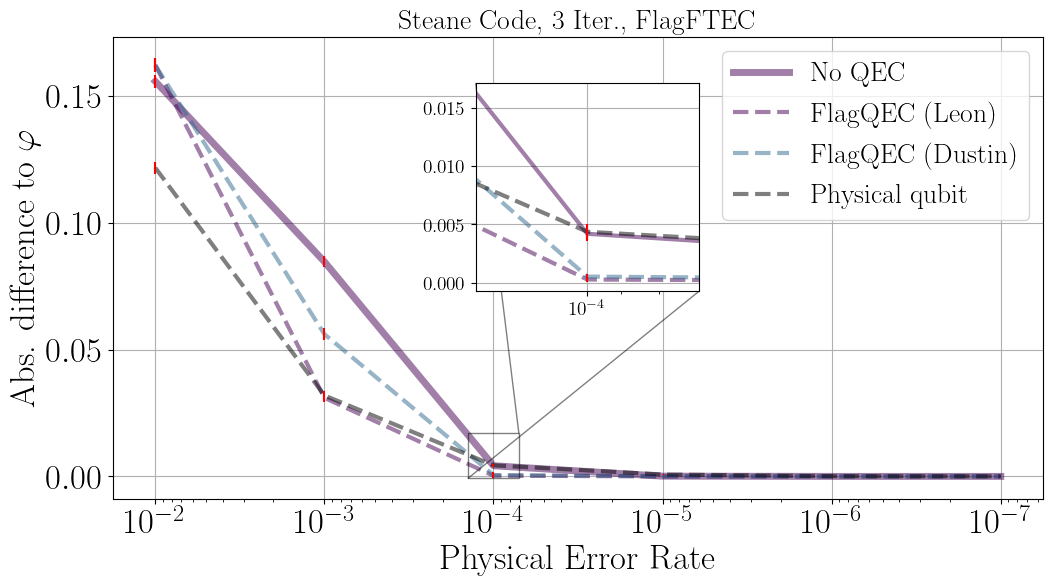

In [6]:
# Zoom-Fenster um p=1e-4 für den Steane-Crossover-Plot oben (nutzt fig, ax1, p1, p2, p6, y.. aus der Zelle darüber)
import copy

fig_zoom = copy.deepcopy(fig)
ax_main = fig_zoom.axes[0]

p_zoom = 1e-4
x_lo, x_hi = p_zoom/10**0.15, p_zoom*10**0.15

# nur FlagQEC (Leon), FlagQEC (Dustin) und Physical qubit (schwarz) im Zoom
curves = [
    (p1, y1, err1, dict(linestyle="-", color=colors[0], linewidth=3)),
    (p1, y_qec1, err_qec1, dict(linestyle="--", color=colors[0], linewidth=3)),
    (p2, y_qec2, err_qec2, dict(linestyle="--", color=colors[2], linewidth=3)),
    (p6, y6,     err6,     dict(linestyle="--", color="black",   linewidth=3)),
]

axins = ax_main.inset_axes([0.39, 0.45, 0.24, 0.45])
y_vals = []
for p, y, err, style in curves:
    axins.plot(p, y, alpha=0.5, **style)
    axins.errorbar(p, y, yerr=err, ecolor="red", linestyle="")
    # y-Werte im Fenster (lineare Interpolation in log(p), wie im Plot) für die y-Limits
    order = np.argsort(p)
    y_vals += list(np.interp(np.log10([x_lo, p_zoom, x_hi]), np.log10(p[order]), y[order]))
    at_zoom = np.isclose(p, p_zoom)
    y_vals += list(y[at_zoom] + err[at_zoom]) + list(y[at_zoom] - err[at_zoom])

axins.set_xscale("log")
axins.set_xlim(x_lo, x_hi)
axins.invert_xaxis()
axins.xaxis.set_minor_formatter(plt.NullFormatter())
y_min, y_max = min(y_vals), max(y_vals)
axins.set_ylim(y_min - 0.05*(y_max-y_min), y_max + 0.05*(y_max-y_min))
axins.tick_params(axis='both', which='both', labelsize=14)
axins.grid()
ax_main.indicate_inset_zoom(axins, edgecolor="black")

# fig_zoom.savefig("27.png", bbox_inches="tight", dpi=200)
display(fig_zoom)
plt.close(fig_zoom)